In [127]:
# Importing relevant libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [128]:
# Importing dataset
# Attach dataset

data = pd.read_csv("loan_approval_dataset.csv")
df = data.copy()
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [129]:
df.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [131]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [132]:
df.columns

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')

In [133]:
df[" education"].value_counts()

 education
 Graduate        2144
 Not Graduate    2125
Name: count, dtype: int64

## Data Preprocessing

In [134]:
# To check the data columns for white spaces

print(df.columns.tolist())                    # To convert outline to list and show the space in the header
print(df[" self_employed"].unique())          # shows e.g. array([' No', ' Yes'], dtype=object)

['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']
[' No' ' Yes']


In [135]:
# Removes the spaces inbetween the column words.

df.columns = df.columns.str.strip()
print(df.columns.tolist())

# Remove the spaces in each column of the dataset
for col in df.select_dtypes(include = "object").columns:
    df[col] = df[col].str.strip()

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [136]:
df["education"] = df["education"].map({
    "Graduate": 1,
    "Not Graduate": 0
})
df["education"].value_counts()

education
1    2144
0    2125
Name: count, dtype: int64

In [137]:
df["self_employed"] = df["self_employed"].map({
  "No": 0,
  "Yes": 1  
})

df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

In [138]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


## Feature Engineering

In [139]:
df.describe()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,4269.000000,4269.000000,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03,4269.000000
mean,2135.000000,2.498712,0.502225,0.503631,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06,0.622160
std,1232.498479,1.695910,0.500054,0.500045,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06,0.484904
min,1.000000,0.000000,0.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00,0.000000
25%,1068.000000,1.000000,0.000000,0.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06,0.000000
50%,2135.000000,3.000000,1.000000,1.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06,1.000000
75%,3202.000000,4.000000,1.000000,1.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06,1.000000
max,4269.000000,5.000000,1.000000,1.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07,1.000000


In [ ]:
# We check for the minimum and maximum value. Observe there is a negative number in the dataset.

print(df["residential_assets_value"].min())
print(df["residential_assets_value"].max())

-100000
29100000


In [141]:
# Loan approval is fundamentally about repayment capacity vs. requested amount. 
# The raw columns don't express that; ratios do.

df["total_assets"] = (df["residential_assets_value"]
                      + df["commercial_assets_value"]
                      + df["luxury_assets_value"]
                      + df["bank_asset_value"])

df["loan_to_income"] = df["loan_amount"]/df["income_annum"]
df["loan_to_assets"] = df["loan_amount"]/df["total_assets"]
df["assets_to_income"] = df["total_assets"]/df["income_annum"]

# Liquidity check
df["liquid_to_assets"] = df["bank_asset_value"]/df["total_assets"]

# Per-term obligation
df["loan_per_year"] = df["loan_amount"]/df["loan_term"]
df["loan_per_year_to_income"] = df["loan_per_year"]/df["income_annum"]

In [142]:
# Residential assets value contains a negative. which needs to be removed

df.loc[df["residential_assets_value"] < 0, "residential_assets_value"] = np.nan


print(df["residential_assets_value"].min(), df["residential_assets_value"].max())
print(df["total_assets"].min(), df["total_assets"].max())
print(df["assets_to_income"].min(), df["assets_to_income"].max())
print(df["liquid_to_assets"].min(), df["liquid_to_assets"].max())

df["residential_assets_value"] = df["residential_assets_value"].replace(np.nan, 0)
df["total_assets"] = df["total_assets"].replace(np.nan, 0)
df["assets_to_income"] = df["assets_to_income"].replace(np.nan, 0)
df["liquid_to_assets"] = df["liquid_to_assets"].replace(np.nan, 0)
df["loan_to_assets"] = df["loan_to_assets"].replace(np.nan, 0)

0.0 29100000.0
400000 90700000
2.0 10.142857142857142
0.0 0.5


In [ ]:
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
total_assets                0
loan_to_income              0
loan_to_assets              0
assets_to_income            0
liquid_to_assets            0
loan_per_year               0
loan_per_year_to_income     0
dtype: int64

In [144]:
# We drop loan_id

df = df.drop(columns = ["loan_id"])
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,total_assets,loan_to_income,loan_to_assets,assets_to_income,liquid_to_assets,loan_per_year,loan_per_year_to_income
0,2,1,0,9600000,29900000,12,778,2400000.0,17600000,22700000,8000000,1,50700000,3.114583,0.589744,5.281250,0.157791,2.491667e+06,0.259549
1,0,0,1,4100000,12200000,8,417,2700000.0,2200000,8800000,3300000,0,17000000,2.975610,0.717647,4.146341,0.194118,1.525000e+06,0.371951
2,3,1,0,9100000,29700000,20,506,7100000.0,4500000,33300000,12800000,0,57700000,3.263736,0.514731,6.340659,0.221837,1.485000e+06,0.163187
3,3,1,0,8200000,30700000,8,467,18200000.0,3300000,23300000,7900000,0,52700000,3.743902,0.582543,6.426829,0.149905,3.837500e+06,0.467988
4,5,0,1,9800000,24200000,20,382,12400000.0,8200000,29400000,5000000,0,55000000,2.469388,0.440000,5.612245,0.090909,1.210000e+06,0.123469


## Exploratory Data Analysis

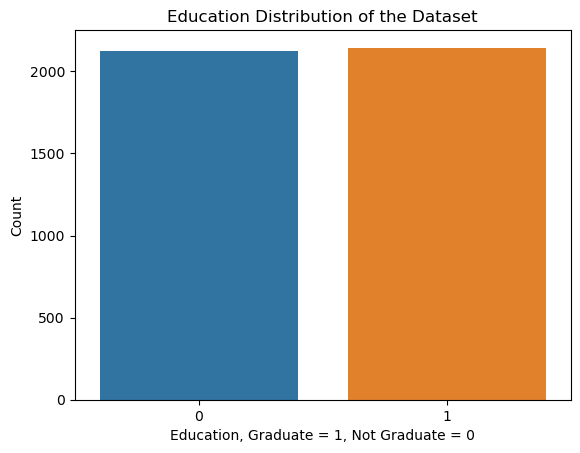

In [145]:
# To visualize the distribution of education in the dataset.

sns.countplot(x="education", data=df)
plt.title("Education Distribution of the Dataset")
plt.xlabel("Education, Graduate = 1, Not Graduate = 0")
plt.ylabel("Count")
plt.show()


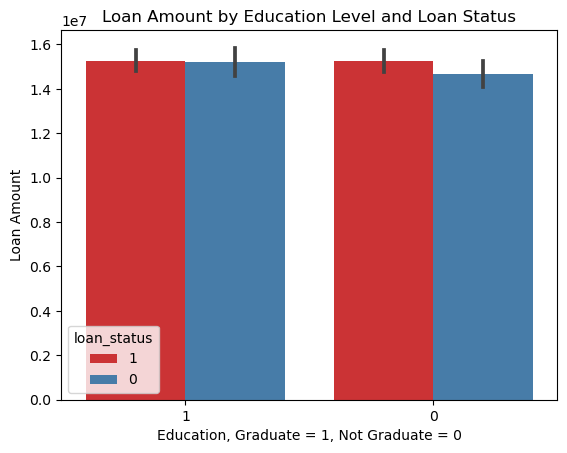

In [146]:
# To obtain a bar plot of the loan amount by education level, with loan status as the hue.

sns.barplot(x = df["education"].astype(str), y = df["loan_amount"], hue = df["loan_status"].astype(str), data = df, palette = "Set1")
plt.title("Loan Amount by Education Level and Loan Status")
plt.xlabel("Education, Graduate = 1, Not Graduate = 0")
plt.ylabel("Loan Amount")
plt.show()


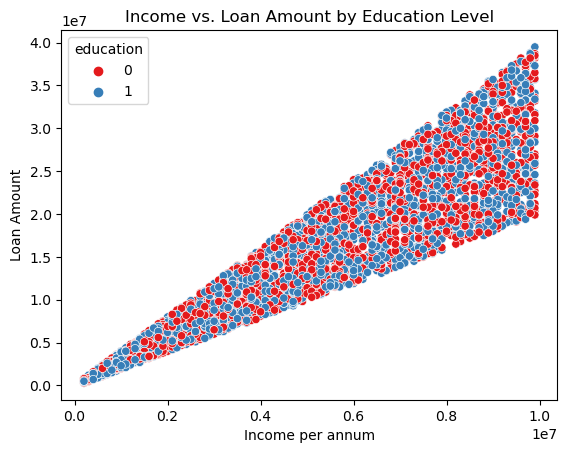

In [147]:
# To obtain a scatter plot of income vs. loan amount, with education level as the hue.

scatterplot = sns.scatterplot(x="income_annum", y="loan_amount", data=df, hue="education", palette="Set1")
plt.title("Income vs. Loan Amount by Education Level")
plt.xlabel("Income per annum")
plt.ylabel("Loan Amount")
plt.show()

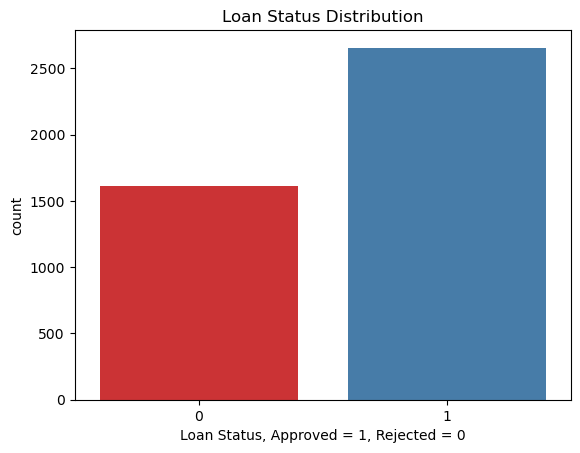

In [148]:
# To obtain a count plot of loan status.

sns.countplot(x = "loan_status", data = df, palette = "Set1")
plt.title("Loan Status Distribution")
plt.xlabel("Loan Status, Approved = 1, Rejected = 0")
plt.show()

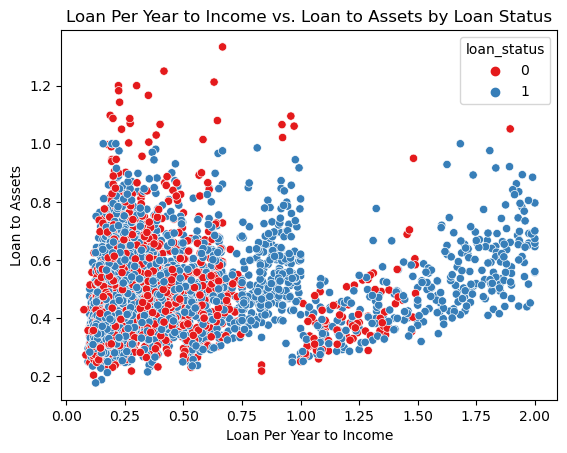

In [149]:
sns.scatterplot(x = "loan_per_year_to_income", y = "loan_to_assets", data = df, hue = "loan_status", palette = "Set1")
plt.title("Loan Per Year to Income vs. Loan to Assets by Loan Status")
plt.xlabel("Loan Per Year to Income")
plt.ylabel("Loan to Assets")
plt.show()

# Model Development

In [150]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [151]:
df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,total_assets,loan_to_income,loan_to_assets,assets_to_income,liquid_to_assets,loan_per_year,loan_per_year_to_income
0,2,1,0,9600000,29900000,12,778,2400000.0,17600000,22700000,8000000,1,50700000,3.114583,0.589744,5.281250,0.157791,2.491667e+06,0.259549
1,0,0,1,4100000,12200000,8,417,2700000.0,2200000,8800000,3300000,0,17000000,2.975610,0.717647,4.146341,0.194118,1.525000e+06,0.371951
2,3,1,0,9100000,29700000,20,506,7100000.0,4500000,33300000,12800000,0,57700000,3.263736,0.514731,6.340659,0.221837,1.485000e+06,0.163187
3,3,1,0,8200000,30700000,8,467,18200000.0,3300000,23300000,7900000,0,52700000,3.743902,0.582543,6.426829,0.149905,3.837500e+06,0.467988
4,5,0,1,9800000,24200000,20,382,12400000.0,8200000,29400000,5000000,0,55000000,2.469388,0.440000,5.612245,0.090909,1.210000e+06,0.123469


In [152]:
x = df.drop(columns = ["loan_status"])
y = df["loan_status"]

In [ ]:
# Split the dataset into training and testing sets, with 80% of the data used for training and 20% for testing. The stratify parameter ensures that the class distribution in the target variable is preserved in both the training and testing sets.

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(3415, 18) (854, 18) (3415,) (854,)


In [159]:
# We scale the features to ensure that they are on a similar scale, which can improve the performance of some machine learning algorithms.
# Note that you should fit the scaler on the training data and then transform both the training and testing data to avoid data leakage.

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

## Logistic Regression 

In [214]:
log_model = LogisticRegression()
model = log_model.fit(x_train_scaled, y_train)

In [ ]:
# We obtain the training accuracy of the model by predicting the target variable on the training data and comparing it to the actual values.

Y_train_prediction = model.predict(x_train_scaled)
training_data_accuracy = accuracy_score(y_train, Y_train_prediction)

print("Training Data Accuracy (Y_Predicted values):", training_data_accuracy)

Training Data Accuracy (Y_Predicted values): 0.9370424597364568


In [218]:
# We obtain the performance testing accuracy of the model by predicting the target variable on the testing data and comparing it to the actual values.

y_test_prediction = model.predict(x_test_scaled)
test_accuracy_logist = accuracy_score(y_test, y_test_prediction)
print("Testing Data Accuracy (Y_Predicted values):", test_accuracy_logist)

Testing Data Accuracy (Y_Predicted values): 0.9320843091334895


In [166]:
# Obtaining the classification report and confusion matrix for the testing data predictions.

print(classification_report(y_test, y_test_prediction))
print(classification_report(y_test, y_test_prediction))

              precision    recall  f1-score   support

           0       0.92      0.89      0.91       323
           1       0.94      0.95      0.95       531

    accuracy                           0.93       854
   macro avg       0.93      0.92      0.93       854
weighted avg       0.93      0.93      0.93       854

              precision    recall  f1-score   support

           0       0.92      0.89      0.91       323
           1       0.94      0.95      0.95       531

    accuracy                           0.93       854
   macro avg       0.93      0.92      0.93       854
weighted avg       0.93      0.93      0.93       854



In [170]:
# Obtaining a plot of the confusion matrix for the testing data predictions.

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

In [ ]:
# Obtaining the confusion matrix for the testing data predictions.

cm = confusion_matrix(y_test, y_test_prediction)
cm

array([[289,  34],
       [ 24, 507]], dtype=int64)

<Axes: >

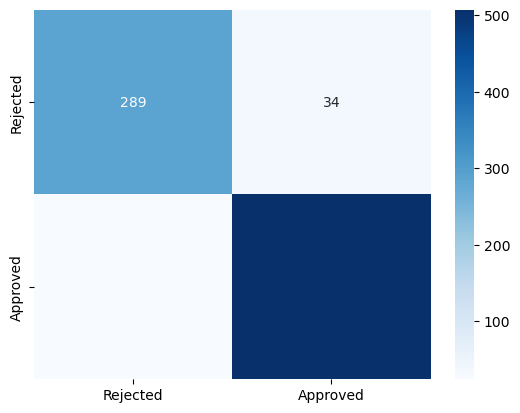

In [184]:
# To plot the confusion matrix as a heatmap using seaborn, we define the label names for the classes and create a confusion matrix with the specified labels. We then use sns.heatmap to visualize the confusion matrix with annotations, formatting, and color mapping.

label_names = ["Rejected", "Approved"]
cm = confusion_matrix(y_test, y_test_prediction, labels = [0, 1])
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", xticklabels = label_names, yticklabels = label_names)

## Support Vector Machine

In [186]:
svm = svm.SVC()

In [188]:
# Fitting the SVM model on the dataset

svm_model = svm.fit(x_train_scaled, y_train)

In [189]:
# Obtaining the Y_train accuracy

y_train_prediction = svm_model.predict(x_train_scaled)
y_train_accuracy = accuracy_score(y_train, y_train_prediction)
print("Y_train_accuracy:", y_train_accuracy)

Y_train_accuracy: 0.9710102489019034


In [217]:
# Obtaining the Y_test accuracy

y_test_prediction = svm_model.predict(x_test_scaled)
y_test_accuracy_SVM = accuracy_score(y_test, y_test_prediction)
print("Y_test_accuracy:", y_test_accuracy_SVM)

Y_test_accuracy: 0.9531615925058547


In [193]:
print(classification_report(y_test, y_test_prediction))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       323
           1       0.96      0.97      0.96       531

    accuracy                           0.95       854
   macro avg       0.95      0.95      0.95       854
weighted avg       0.95      0.95      0.95       854



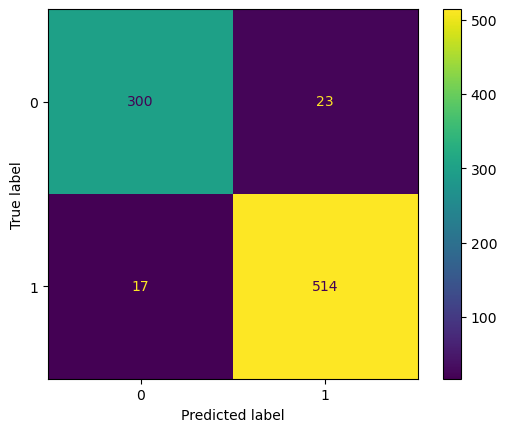

In [191]:
cm = confusion_matrix(y_test, y_test_prediction)
cm_display = ConfusionMatrixDisplay(cm).plot()

# Random Forest Model

In [196]:
random_forest = RandomForestClassifier()
random_forest_model = random_forest.fit(x_train_scaled, y_train)

In [ ]:
# Performance accuracy on the training set

y_train_prediction = random_forest_model.predict(x_train_scaled)
y_train_accuracy = accuracy_score(y_train, y_train_prediction)
print("Y_train_accuracy:", y_train_accuracy)

Y_train_accuracy: 1.0


In [220]:
# Performance test on the testing set

y_test_prediction = random_forest_model.predict(x_test_scaled)
y_test_accuracy_RF = accuracy_score(y_test, y_test_prediction)
print("Y_Test_Accuracy:", y_test_accuracy_RF)

Y_Test_Accuracy: 0.9988290398126464


In [200]:
# Classification accuracy of the dataset

print(classification_report(y_test, y_test_prediction))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       323
           1       1.00      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854



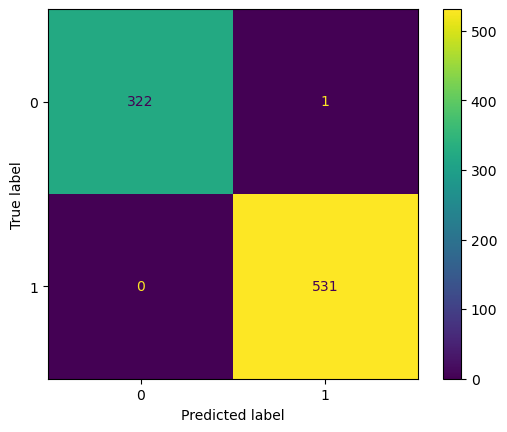

In [205]:
# Confusion matrix

cm = confusion_matrix(y_test, y_test_prediction)
cm_display = ConfusionMatrixDisplay(cm).plot()

## XGBoost Classifier

In [ ]:
# Fitting the XGBoost model on the dataset

xgb = XGBClassifier()
xgb_model = xgb.fit(x_train_scaled, y_train)

In [209]:
# Obtaining the accuracy on the training dataset

y_train_prediction = xgb_model.predict(x_train_scaled)
y_train_accuracy = accuracy_score(y_train, y_train_prediction)
print("Y_train_accuracy:", y_train_accuracy)

Y_train_accuracy: 1.0


In [222]:
# Obtaining the accuracy on the testing dataset

y_test_prediction = xgb_model.predict(x_test_scaled)
y_test_accuracy_XGB = accuracy_score(y_test, y_test_prediction)
print("Y_test_accuracy:", y_test_accuracy_XGB)

Y_test_accuracy: 0.9976580796252927


In [212]:
# Obtaining the classification report and confusion matrix for the testing data predictions.

print(classification_report(y_test, y_test_prediction))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       323
           1       1.00      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      1.00      1.00       854
weighted avg       1.00      1.00      1.00       854



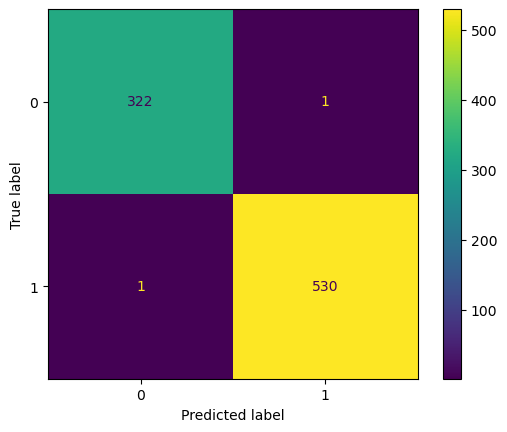

In [213]:
# Obtaining the confusion matrix

cm = confusion_matrix(y_test, y_test_prediction)
cm_display = ConfusionMatrixDisplay(cm).plot()

In [223]:
## Comparing the accuracy value of the four models

print("Accuracy of Logistic regression:", test_accuracy_logist)
print("Accuracy of Support Vector Machine:", y_test_accuracy_SVM)
print("Accuracy of Random Forest Model:", y_test_accuracy_RF)
print("Accuracy of XGBoost Model:", y_test_accuracy_XGB)

Accuracy of Logistic regression: 0.9320843091334895
Accuracy of Support Vector Machine: 0.9531615925058547
Accuracy of Random Forest Model: 0.9988290398126464
Accuracy of XGBoost Model: 0.9976580796252927
